# B — BART-MNLI zero-shot: kiểm số từ scores đã lưu
    **Phạm vi:** lần chạy này tính lại metric trên toàn bộ validation/test từ scores
    NLI lịch sử; không nạp lại BART hoặc chạy mới 28 cặp NLI cho mỗi câu.
    B không fine-tune trọng số bằng GoEmotions. Ngưỡng đã khóa từ validation.
    Mỗi bảng dưới được tính/kiểm khi chạy cell, không chép số dự kiến vào notebook.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions, multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
ARTIFACTS = artifacts_root()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0])
print('Dataset revision:', REVISION)
print('Artifacts:', ARTIFACTS.name)

Python: 3.13.9
Dataset revision: add492243ff905527e67aeb8b80c082af02207c3
Artifacts: goemotions-multilabel-classification


## 1. Checkpoint, revision, template và trạng thái run thật

In [2]:
from src.models.zero_shot import CHECKPOINT, HYPOTHESIS_TEMPLATE
B = ARTIFACTS/'data/processed/zero_shot/full'
metadata = read_json(B/'run_metadata.json')
protocol = read_json(B/'final_protocol.json')
assert metadata['checkpoint'] == CHECKPOINT and metadata['multi_label']
assert metadata['status'] == 'complete' and not metadata['smoke']
display(pd.Series({k: metadata[k] for k in ('checkpoint', 'model_revision',
    'hypothesis_template', 'dtype', 'device', 'sample_count', 'created_at_utc')}))
print('Fine-tune trọng số: KHÔNG. Tìm ngưỡng: đã thực hiện trên validation trước test.')

checkpoint                             facebook/bart-large-mnli
model_revision         d7645e127eaf1aefc7862fd59a17a5aa8558b8ce
hypothesis_template                     This text expresses {}.
dtype                                                   float16
device                                                     cuda
sample_count                                               5426
created_at_utc                 2026-10-08T15:14:08.822646+00:00
dtype: object

Fine-tune trọng số: KHÔNG. Tìm ngưỡng: đã thực hiện trên validation trước test.


## 2. Kiểm dataset, checkpoint/protocol và toàn bộ scores
    Hàm dùng chung kiểm hash, mapping và ID; tính lại đủ 72 dòng toàn đồ án.
    Trong notebook này chỉ trình bày sáu dòng của B. Thiếu/sai artifact sẽ dừng.

In [3]:
from src.notebook_support import benchmark
from src.models.baseline import load_aligned_scores
verified, frames, labels = benchmark(str(ARTIFACTS))
b_rows = pd.DataFrame([r for r in verified['records'] if r['system'] == 'B_bart_mnli'])
assert len(b_rows) == 6
display(b_rows)
print('Sai lệch metric lớn nhất với CSV báo cáo:', verified['metric_max_absolute_difference'])

PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật


PASS C: bert seed 42


PASS C: bert seed 123


PASS C: bert seed 2026


...

PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss
0,B_bart_mnli,None,validation,fixed,5426,0.105982,0.102665,0.065237,0.893591,0.055256,0.722884,0.530659
1,B_bart_mnli,None,validation,global,5426,0.150195,0.146667,0.099777,0.763511,0.083926,0.581034,0.283924
2,B_bart_mnli,None,validation,tuned,5426,0.163272,0.176173,0.098974,0.790313,0.099767,0.752351,0.295482
3,B_bart_mnli,None,test,fixed,5427,0.103490,0.100751,0.063465,0.893504,0.054195,0.714805,0.531456
4,B_bart_mnli,None,test,global,5427,0.147298,0.144922,0.095979,0.761396,0.082890,0.575920,0.283062
5,B_bart_mnli,None,test,tuned,5427,0.160881,0.175184,0.097248,0.787248,0.099177,0.749881,0.294105


Sai lệch metric lớn nhất với CSV báo cáo: 0.0


## 3. Ghép scores theo ID và lấy một ví dụ NLI thật
    HF trả nhãn theo điểm giảm dần. Cell kiểm cách khôi phục đúng thứ tự 28 cột
    bằng một hàng scores thật. Đây là kiểm mapping, không phải suy luận BART mới.

In [4]:
from src.models.zero_shot import map_pipeline_scores
val = frames['validation']
val_scores = load_aligned_scores(B/'validation_scores.npz', val.id.tolist(), labels)
i = 0
order = np.argsort(-val_scores[i])
hf_order = {'labels': [labels[j] for j in order], 'scores': val_scores[i, order].tolist()}
np.testing.assert_array_equal(map_pipeline_scores(hf_order, labels)[0], val_scores[i])
print('ID:', val.id.iloc[i], '\nVăn bản:', val.text.iloc[i])
print('Nhãn thật:', [labels[j] for j in val.labels.iloc[i]])
display(pd.DataFrame({'label': labels, 'NLI_score': val_scores[i]}).sort_values('NLI_score', ascending=False))

ID: edgurhb 
Văn bản: Is this in New Orleans?? I really feel like this is New Orleans.
Nhãn thật: ['neutral']


,label,NLI_score
6,confusion,0.999550
26,surprise,0.999115
7,curiosity,0.998952
19,nervousness,0.995032
8,desire,0.993587
13,excitement,0.972283
14,fear,0.956685
3,annoyance,0.951751
0,admiration,0.949786
22,realization,0.940134


## 4. Tính metric và phân tích nhãn dự đoán quá nhiều
    Scores NLI chưa được hiệu chuẩn thành xác suất cảm xúc. Kết quả B thấp được giữ
    nguyên; không đổi template/ngưỡng theo test để làm đẹp số đã báo cáo.

In [5]:
metrics = evaluate_multilabel(multi_hot(val.labels.tolist()), val_scores, labels, 0.5)
np.testing.assert_allclose([metrics[k] for k in METRIC_NAMES],
                           [metadata['metrics'][k] for k in METRIC_NAMES], atol=1e-12, rtol=0)
display(pd.Series({k: metrics[k] for k in (*METRIC_NAMES, 'mean_predicted_labels', 'empty_prediction_count')}))
display(pd.DataFrame(metrics['per_label'])[['label', 'support', 'predicted_support', 'precision', 'recall', 'f1']])

macro_f1                   0.105982
micro_f1                   0.102665
macro_precision            0.065237
macro_recall               0.893591
micro_precision            0.055256
micro_recall               0.722884
hamming_loss               0.530659
mean_predicted_labels     15.382602
empty_prediction_count     2.000000
dtype: float64

,label,support,predicted_support,precision,recall,f1
0,admiration,488,2795,0.158855,0.909836,0.270484
1,amusement,303,3353,0.088876,0.983498,0.163020
2,anger,195,3415,0.055051,0.964103,0.104155
3,annoyance,303,3940,0.074873,0.973597,0.139053
4,approval,397,3175,0.100787,0.806045,0.179171
5,caring,153,3032,0.041887,0.830065,0.079749
6,confusion,152,4599,0.032398,0.980263,0.062724
7,curiosity,248,4398,0.055707,0.987903,0.105467
8,desire,77,4025,0.019130,1.000000,0.037543
9,disappointment,163,3387,0.046058,0.957055,0.087887


## 5. So sánh ba ngưỡng đã khóa trên validation và test

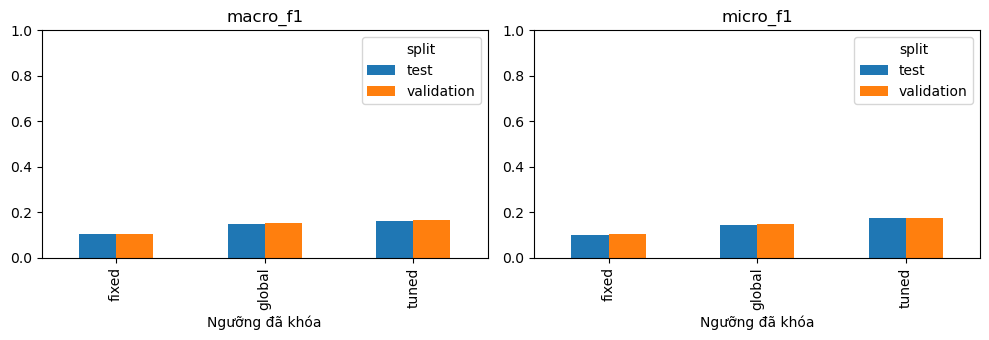

B chỉ có một run; không tạo mean±std từ một run.


In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ('macro_f1', 'micro_f1')):
    b_rows.pivot(index='threshold_mode', columns='split', values=metric).plot.bar(ax=ax)
    ax.set_title(metric); ax.set_ylim(0, 1); ax.set_xlabel('Ngưỡng đã khóa')
plt.tight_layout(); plt.show(); plt.close()
print('B chỉ có một run; không tạo mean±std từ một run.')

## 6. Cách chạy lại suy luận NLI khi cần
    Code thực thi nằm tại `scripts/zero_shot/run_zero_shot.py`: nạp pretrained,
    tạo 28 giả thuyết, dự đoán `multi_label=True`, ghép nhãn và lưu từng batch.
    Một lượt full trước đây mất khoảng 19 phút cho validation trên máy chạy.
    Notebook đã chạy này dùng lại scores đó và đã đối chiếu đủ sáu dòng B.

In [7]:
print('Đã tính lại B từ scores lịch sử:', len(b_rows), 'dòng; số mẫu theo split:')
display(b_rows.groupby('split')['n_samples'].first())
print('NLI inference mới trong notebook này: KHÔNG; huấn luyện lại: KHÔNG.')

Đã tính lại B từ scores lịch sử: 6 dòng; số mẫu theo split:


split
test          5427
validation    5426
Name: n_samples, dtype: int64

NLI inference mới trong notebook này: KHÔNG; huấn luyện lại: KHÔNG.
